# 04 · Inferential Statistics
Module 2.2 (Inferential Statistics)

Descriptive statistics describe **our sample** of 918 patients. **Inferential statistics** use the sample to draw
conclusions about the **whole population** of similar patients, and tell us how likely it is that a difference we see
is just due to chance.

**The general recipe of a hypothesis test**
1. State the **null hypothesis H0** (no effect / no difference) and the **alternative H1**.
2. Choose a **significance level α = 0.05** (we accept a 5% risk of a false alarm).
3. Compute a **test statistic** from the data and its **p-value** = probability of seeing a result at least this extreme if H0 were true.
4. **Decision:** if p < α, reject H0 (the effect is *statistically significant*); otherwise we fail to reject H0.

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
from scipy import stats as sps
from src import stats as S

## 1. Load the data
Cleaned data: impossible zeros in Cholesterol and RestingBP are missing and are skipped in each test.

In [2]:
df = data.load_clean()
print(df.shape)

(918, 12)


## 2. Normality check
Many classical tests (t-test, ANOVA) assume the data in each group is roughly **normally distributed**.

### 2.1 Q-Q plots
A **Q-Q (quantile-quantile) plot** compares the quantiles of our data with the quantiles of a perfect normal distribution.
If the data is normal, the points lie on the straight line. Curves at the ends mean skewness or heavy tails.

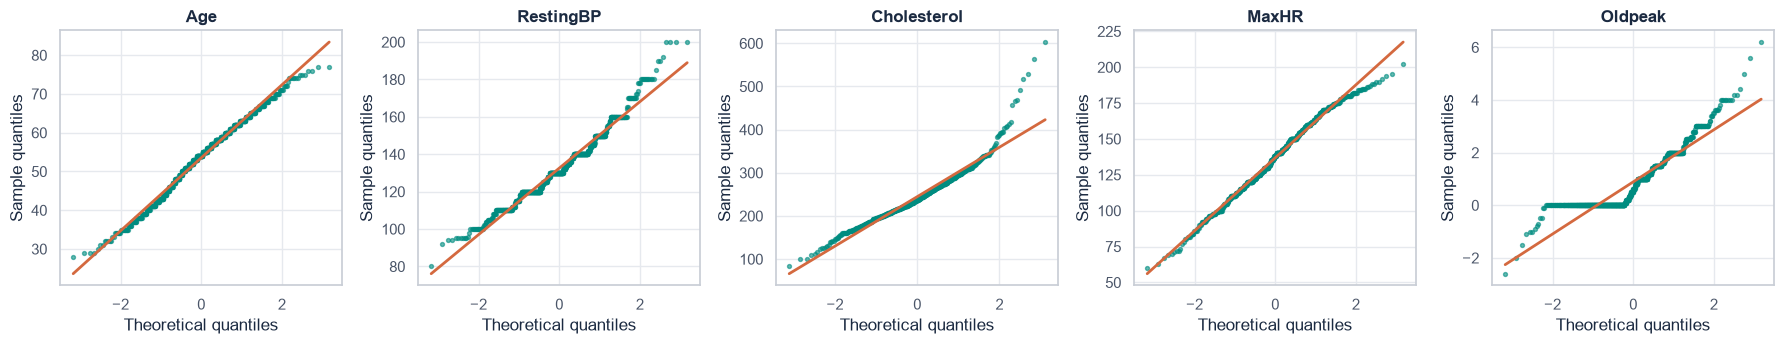

In [3]:
fig = plots.qq_grid(df, C.CONTINUOUS)
plots.save_fig(fig, "04_qq_plots")
plt.show()

### 2.2 Shapiro-Wilk test
* H0: the feature is normally distributed
* H1: the feature is not normally distributed

A small p-value (< 0.05) means we reject normality.

In [4]:
shapiro = []
for col in C.CONTINUOUS:
    r = S.shapiro_test(df[col], col)
    shapiro.append({"Feature": col, "n": r["n"], "W statistic": round(r["statistic"], 4),
                    "p-value": S.fmt_p(r["p_value"]), "Normal at α = 0.05?": "No" if r["significant"] else "Yes"})
pd.DataFrame(shapiro)

,Feature,n,W statistic,p-value,Normal at α = 0.05?
0,Age,918,0.991,< 0.001,No
1,RestingBP,917,0.971,< 0.001,No
2,Cholesterol,746,0.936,< 0.001,No
3,MaxHR,918,0.993,< 0.001,No
4,Oldpeak,918,0.860,< 0.001,No


**Interpretation:** with large samples (n ≈ 900) Shapiro-Wilk detects even tiny departures from normality, so all features
are formally "not normal". The Q-Q plots show that **Age and MaxHR are close to normal**, while Oldpeak and Cholesterol are clearly skewed.
Because our groups are large (n > 400 each), the **Central Limit Theorem** (section 8) tells us the *sample means* are still
approximately normal, so t-tests and ANOVA on the means remain reliable.

## 3. Two-sample Welch t-test
We compare the **mean** of a feature between two independent groups: patients **without** (0) and **with** (1) heart disease.
The **Welch** version does not assume the two groups have equal variances, which is safer here.

$$ t = \frac{\bar x_0 - \bar x_1}{\sqrt{\dfrac{s_0^2}{n_0} + \dfrac{s_1^2}{n_1}}} $$

First, a quick look at the group variances (to justify Welch over the classic Student t-test):

In [5]:
df.groupby(C.TARGET)[["MaxHR", "Age"]].agg(["mean", "std", "count"]).round(2)

MaxHR                 Age            
                mean    std count   mean   std count
HeartDisease                                        
0            148.150 23.290   410 50.550 9.440   410
1            127.660 23.390   508 55.900 8.730   508

We also run **Levene's test** for equal variances (H0: variances are equal):

In [6]:
for col in ["MaxHR", "Age"]:
    stat, p = sps.levene(df.loc[df[C.TARGET] == 0, col], df.loc[df[C.TARGET] == 1, col])
    print(f"Levene {col:6s}: W = {stat:.3f}, p = {S.fmt_p(p)} -> {'unequal' if p < 0.05 else 'no evidence of unequal'} variances")

Levene MaxHR : W = 0.015, p = 0.9016 -> no evidence of unequal variances
Levene Age   : W = 5.410, p = 0.0202 -> unequal variances


For MaxHR the variances are almost identical, while for Age they differ. Welch's test is a safe default in both cases:
when the variances are equal it gives practically the same answer as Student's t-test, and when they differ it stays correct.

### 3.1 MaxHR
* **H0:** the mean MaxHR is the same for patients with and without heart disease (μ₀ = μ₁)
* **H1:** the mean MaxHR is different (μ₀ ≠ μ₁)
* **α = 0.05**, two-tailed

In [7]:
def show_test(r):
    print(f"Test        : {r['test']}")
    print(f"H0          : {r['h0']}")
    print(f"H1          : {r['h1']}")
    print(f"Statistic   : {r['statistic']:.4f}")
    print(f"p-value     : {r['p_value']:.3e}")
    print(f"α           : {r['alpha']}")
    print(f"Significant : {'YES' if r['significant'] else 'NO'}")
    print(f"Conclusion  : {r['conclusion']}")

t_maxhr = S.welch_ttest(df, "MaxHR")
show_test(t_maxhr)

Test        : Welch two-sample t-test
H0          : mean MaxHR is the same in both groups (μ₀ = μ₁)
H1          : mean MaxHR differs between the groups (μ₀ ≠ μ₁)
Statistic   : 13.2315
p-value     : 1.431e-36
α           : 0.05
Significant : YES
Conclusion  : p < 0.001 (below α = 0.05), so we reject H0. The average MaxHR is significantly different between patients with no heart disease (148.2) and heart disease (127.7).


### 3.2 Age
* **H0:** the mean age is the same in both groups
* **H1:** the mean age is different
* **α = 0.05**, two-tailed

In [8]:
t_age = S.welch_ttest(df, "Age")
show_test(t_age)

Test        : Welch two-sample t-test
H0          : mean Age is the same in both groups (μ₀ = μ₁)
H1          : mean Age differs between the groups (μ₀ ≠ μ₁)
Statistic   : -8.8225
p-value     : 6.348e-18
α           : 0.05
Significant : YES
Conclusion  : p < 0.001 (below α = 0.05), so we reject H0. The average Age is significantly different between patients with no heart disease (50.6) and heart disease (55.9).


For completeness, the Welch t-test for every continuous feature:

In [9]:
ttests = [(c, S.welch_ttest(df, c)) for c in C.CONTINUOUS]
tbl = S.results_table(ttests)
tbl.insert(2, "Mean (no HD)", [round(r["mean_0"], 2) for _, r in ttests])
tbl.insert(3, "Mean (HD)", [round(r["mean_1"], 2) for _, r in ttests])
tbl

,Variable,Test,Mean (no HD),Mean (HD),Statistic,p-value,Decision (α = 0.05)
0,Age,Welch two-sample t-test,50.550,55.900,-8.823,< 0.001,Reject H0
1,RestingBP,Welch two-sample t-test,130.180,134.450,-3.647,< 0.001,Reject H0
2,Cholesterol,Welch two-sample t-test,238.770,251.060,-2.833,0.0047,Reject H0
3,MaxHR,Welch two-sample t-test,148.150,127.660,13.231,< 0.001,Reject H0
4,Oldpeak,Welch two-sample t-test,0.410,1.270,-14.040,< 0.001,Reject H0


## 3b. One-sample Z-test: is the average resting blood pressure normal?
A **one-sample test** compares the mean of **one** group with a fixed reference value. Clinically, a resting systolic blood
pressure of **120 mm Hg** is the upper limit of "normal". Is the average patient in this dataset above that?

$$ z = rac{ar x - \mu_0}{s / \sqrt{n}} $$

* **H0:** the population mean RestingBP = 120 mm Hg (μ = 120)
* **H1:** the population mean RestingBP ≠ 120 mm Hg (μ ≠ 120)
* **α = 0.05**, two-tailed

**Why a Z-test and not a t-test?** With n = 917 the sample standard deviation is a very accurate estimate of the population σ,
and the t-distribution with 916 degrees of freedom is practically identical to the standard normal distribution.
(For small samples, n < 30, we would use the one-sample t-test instead.)

In [10]:
z_bp = S.one_sample_ztest(df["RestingBP"], 120, "RestingBP")
show_test(z_bp)
print()
print(f"Sample mean = {z_bp['mean']:.2f}, standard error = {z_bp['se']:.3f}, n = {z_bp['n']}")
print(f"Critical value for α = 0.05 (two-tailed): ±{sps.norm.ppf(0.975):.3f}")

Test        : One-sample Z-test
H0          : population mean RestingBP = 120 (μ = 120)
H1          : population mean RestingBP ≠ 120 (μ ≠ 120)
Statistic   : 21.0983
p-value     : 0.000e+00
α           : 0.05
Significant : YES
Conclusion  : p < 0.001 (below α = 0.05), so we reject H0. The average RestingBP (132.54) is significantly higher than the reference value 120.

Sample mean = 132.54, standard error = 0.594, n = 917
Critical value for α = 0.05 (two-tailed): ±1.960


## 4. One-way ANOVA
**ANOVA (Analysis of Variance)** tests whether the means of **two or more** groups are equal by comparing the variation
*between* groups with the variation *within* groups:
$$ F = \frac{\text{variance between group means}}{\text{variance within groups}} $$
A large F (small p) means the group means are further apart than random variation would explain.

### 4.1 Each continuous feature across the target (2 groups)
With only two groups, ANOVA gives the same result as the classic (equal-variance) t-test: $F = t^2$.

In [11]:
anovas = [(c, S.anova_test(df, c)) for c in C.CONTINUOUS]
S.results_table(anovas)

,Variable,Test,Statistic,p-value,Decision (α = 0.05)
0,Age,One-way ANOVA,79.161,< 0.001,Reject H0
1,RestingBP,One-way ANOVA,12.918,< 0.001,Reject H0
2,Cholesterol,One-way ANOVA,8.114,0.0045,Reject H0
3,MaxHR,One-way ANOVA,174.914,< 0.001,Reject H0
4,Oldpeak,One-way ANOVA,178.615,< 0.001,Reject H0


### 4.2 MaxHR across ChestPainType (4 groups)
* **H0:** mean MaxHR is the same for all four chest-pain types (ASY, ATA, NAP, TA)
* **H1:** at least one chest-pain type has a different mean MaxHR
* **α = 0.05**

In [12]:
a_cp = S.anova_test(df, "MaxHR", "ChestPainType")
show_test(a_cp)

Test        : One-way ANOVA
H0          : mean MaxHR is equal in every ChestPainType group
H1          : at least one ChestPainType group has a different mean MaxHR
Statistic   : 47.0531
p-value     : 2.787e-28
α           : 0.05
Significant : YES
Conclusion  : p < 0.001 (below α = 0.05), so we reject H0. At least one ChestPainType group has a different mean MaxHR (ASY: 128.5, ATA: 150.2, NAP: 143.2, TA: 147.9).


A box plot makes the group differences visible:

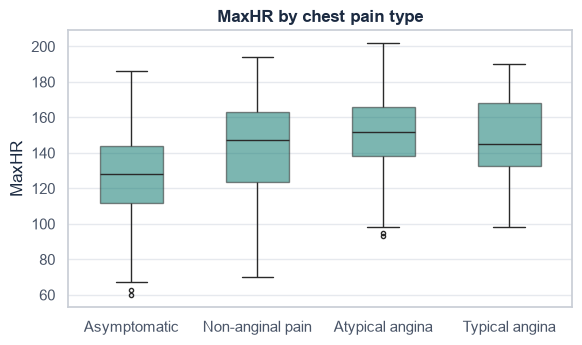

In [13]:
order = ["ASY", "NAP", "ATA", "TA"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.boxplot(data=df, x="ChestPainType", y="MaxHR", order=order, color=C.TEAL, width=0.5, ax=ax,
            boxprops={"alpha": 0.55}, fliersize=3)
ax.set_xticks(range(4), [C.CATEGORY_LABELS["ChestPainType"][o] for o in order])
ax.set_xlabel("")
ax.set_title("MaxHR by chest pain type")
plots.save_fig(fig, "04_anova_maxhr_chestpain")
plt.show()

### 4.3 Cholesterol across ChestPainType (4 groups)
* **H0:** mean cholesterol is the same for all four chest-pain types
* **H1:** at least one type differs

In [14]:
a_chol = S.anova_test(df, "Cholesterol", "ChestPainType")
show_test(a_chol)

Test        : One-way ANOVA


H0          : mean Cholesterol is equal in every ChestPainType group
H1          : at least one ChestPainType group has a different mean Cholesterol
Statistic   : 2.6525
p-value     : 4.768e-02
α           : 0.05
Significant : YES
Conclusion  : p = 0.0477 < 0.05, so we reject H0. At least one ChestPainType group has a different mean Cholesterol (ASY: 250.2, ATA: 242.9, NAP: 237.2, TA: 232.3).


## 5. Chi-square test of independence
For **two categorical variables** we cannot compute means. Instead we build a **contingency table** (counts for every
combination) and compare the **observed** counts with the counts we would **expect** if the variables were independent:
$$ \chi^2 = \sum \frac{(O - E)^2}{E} $$
* **H0:** the feature and heart disease are independent
* **H1:** they are associated

Example contingency table for `ExerciseAngina`:

In [15]:
r = S.chi_square_test(df, "ExerciseAngina")
display(Markdown("**Observed counts**"))
display(r["table"])
display(Markdown("**Expected counts if independent**"))
display(r["expected"].round(1))

**Observed counts**

HeartDisease,0,1
ExerciseAngina,,
N,355,192
Y,55,316


**Expected counts if independent**

HeartDisease,0,1
ExerciseAngina,,
N,244.300,302.700
Y,165.700,205.300


Now the test for every categorical feature. **Cramér's V** (0 = no association, 1 = perfect association) tells us how strong
the association is, because p-values alone only say whether it exists.

In [16]:
chis = [(c, S.chi_square_test(df, c)) for c in C.CATEGORICAL]
chi_tbl = S.results_table(chis)
chi_tbl.insert(3, "dof", [r["dof"] for _, r in chis])
chi_tbl["Cramér's V"] = [round(r["cramers_v"], 3) for _, r in chis]
chi_tbl.sort_values("Cramér's V", ascending=False)

,Variable,Test,Statistic,dof,p-value,Decision (α = 0.05),Cramér's V
5,ST_Slope,Chi-square test of independence,355.918,2,< 0.001,Reject H0,0.623
1,ChestPainType,Chi-square test of independence,268.067,3,< 0.001,Reject H0,0.540
4,ExerciseAngina,Chi-square test of independence,222.259,1,< 0.001,Reject H0,0.492
0,Sex,Chi-square test of independence,84.145,1,< 0.001,Reject H0,0.303
2,FastingBS,Chi-square test of independence,64.321,1,< 0.001,Reject H0,0.265
3,RestingECG,Chi-square test of independence,10.931,2,0.0042,Reject H0,0.109


## 6. 95% confidence intervals for mean MaxHR
A **confidence interval (CI)** gives a range of plausible values for the true population mean:
$$ \bar x \pm t_{0.975,\,n-1}\cdot\frac{s}{\sqrt n} $$
"95% confidence" means: if we repeated the study many times, about 95% of the intervals built this way would contain the true mean.

In [17]:
ci_rows = []
for g in [0, 1]:
    ci = S.mean_ci(df.loc[df[C.TARGET] == g, "MaxHR"])
    ci_rows.append({"Group": C.CLASS_NAMES[g], "n": ci["n"], "Mean": ci["mean"], "Std error": ci["se"],
                    "t critical": ci["t_crit"], "95% CI lower": ci["lower"], "95% CI upper": ci["upper"]})
ci_tbl = pd.DataFrame(ci_rows)
ci_tbl.round(2)

,Group,n,Mean,Std error,t critical,95% CI lower,95% CI upper
0,No heart disease,410,148.150,1.150,1.970,145.890,150.410
1,Heart disease,508,127.660,1.040,1.960,125.620,129.690


The same intervals as a picture: each dot is the group mean and the horizontal bar is its 95% CI.

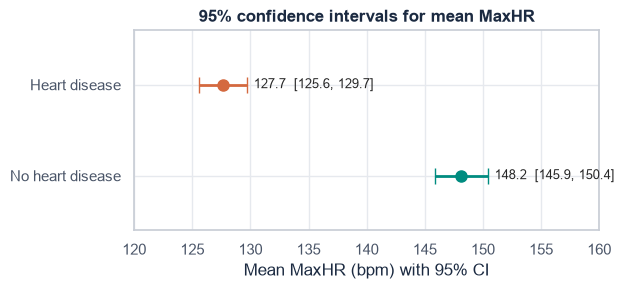

In [18]:
fig, ax = plt.subplots(figsize=(6, 2.6))
for i, row in ci_tbl.iterrows():
    ax.errorbar(row["Mean"], i, xerr=[[row["Mean"] - row["95% CI lower"]], [row["95% CI upper"] - row["Mean"]]],
                fmt="o", color=C.CLASS_COLORS[i], capsize=6, lw=2, ms=8)
    ax.text(row["95% CI upper"] + 0.6, i, f"{row['Mean']:.1f}  [{row['95% CI lower']:.1f}, {row['95% CI upper']:.1f}]",
            va="center", fontsize=9)
ax.set_yticks([0, 1], ci_tbl["Group"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(120, 160)
ax.set_xlabel("Mean MaxHR (bpm) with 95% CI")
ax.set_title("95% confidence intervals for mean MaxHR")
plots.save_fig(fig, "04_confidence_intervals")
plt.show()

The two intervals **do not overlap**, which agrees with the t-test: the difference in MaxHR is not due to chance.

## 7. Type I and Type II errors - in medical terms
Every hypothesis test (and every classifier) can make two kinds of mistakes:

| | Patient is actually **healthy** | Patient actually **has heart disease** |
|---|---|---|
| Test says **"heart disease"** | **Type I error (False Positive)** | Correct (True Positive) |
| Test says **"healthy"** | Correct (True Negative) | **Type II error (False Negative)** |

* **Type I error (α) – false positive:** telling a *healthy* person they have heart disease.
  Consequence: unnecessary anxiety, extra tests (ECG, angiography), cost - but the person is not harmed by the disease.
* **Type II error (β) – false negative:** *missing* a patient who really has heart disease.
  Consequence: the patient goes home untreated and may suffer a heart attack. **This is far more dangerous.**

**Why recall matters more here:** recall (sensitivity) = TP / (TP + FN) is the share of truly sick patients the model catches.
High recall = few Type II errors. In screening we prefer to send a few healthy people for extra tests rather than miss a sick one,
so in notebook 07 we choose the model mainly by **recall**, then F1 (to keep precision reasonable).

In hypothesis testing, α = 0.05 caps the Type I error rate; lowering α makes false alarms rarer but increases β (missed effects).

## 8. Central Limit Theorem (CLT) demo
The **CLT** says: if we take many random samples of size *n* from **any** population (even a skewed one) and compute each sample's mean,
those means form an approximately **normal** distribution centred on the population mean, with standard deviation
$\sigma / \sqrt{n}$ (the *standard error*). It gets more normal as *n* grows.

We demonstrate it with **Cholesterol**, which is right-skewed and heavy-tailed. We draw 5,000 bootstrap samples
(random sampling **with replacement**) of size n = 5, 30 and 100 and plot their means.

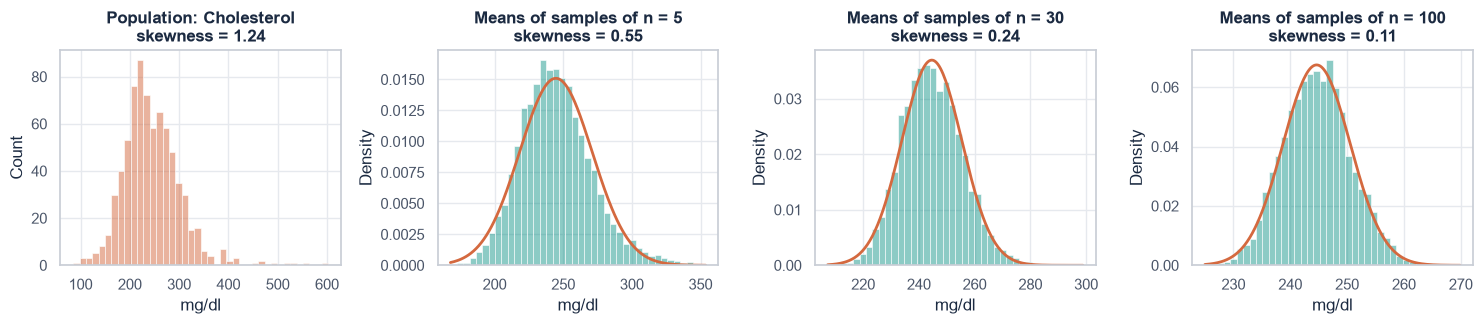

Population mean = 244.64, population SD = 59.11


,Sample size n,Mean of sample means,SD of sample means,Theory σ/√n,Skewness of means
0,5,244.912,26.248,26.437,0.545
1,30,244.637,10.850,10.793,0.238
2,100,244.698,5.923,5.911,0.115


In [19]:
chol = df["Cholesterol"].dropna().to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
sns.histplot(chol, bins=40, ax=axes[0], color=C.CLASS_COLORS[1], alpha=0.5)
axes[0].set_title(f"Population: Cholesterol\nskewness = {sps.skew(chol):.2f}")
clt_rows = []
for ax, n in zip(axes[1:], [5, 30, 100]):
    means = S.bootstrap_means(chol, sample_size=n, n_samples=5000)
    sns.histplot(means, bins=40, stat="density", ax=ax, color=C.TEAL, alpha=0.45)
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, sps.norm.pdf(xs, chol.mean(), chol.std(ddof=0) / np.sqrt(n)), color=C.CLASS_COLORS[1], lw=2)
    ax.set_title(f"Means of samples of n = {n}\nskewness = {sps.skew(means):.2f}")
    clt_rows.append({"Sample size n": n, "Mean of sample means": means.mean(),
                     "SD of sample means": means.std(), "Theory σ/√n": chol.std(ddof=0) / np.sqrt(n),
                     "Skewness of means": sps.skew(means)})
for ax in axes:
    ax.set_xlabel("mg/dl")
fig.tight_layout()
plots.save_fig(fig, "04_clt_bootstrap")
plt.show()
print(f"Population mean = {chol.mean():.2f}, population SD = {chol.std(ddof=0):.2f}")
pd.DataFrame(clt_rows).round(3)

The coral curve is the normal distribution predicted by the CLT. As *n* grows the histogram of sample means matches it
more closely, the skewness shrinks towards 0, and the spread matches $\sigma/\sqrt{n}$ - exactly as the theorem says.

## 9. A note on the Poisson distribution
The **Poisson distribution** models **counts of rare events** in a fixed interval or group, e.g. heart attacks per day in a city,
or patients with a rare finding per clinic session:
$$ P(X = k) = rac{\lambda^k e^{-\lambda}}{k!}, \qquad k = 0, 1, 2, \dots $$
* λ (lambda) = the average number of events per interval. A special property: **mean = variance = λ**.
* It is the limit of the **binomial** distribution when the number of trials *n* is large and the probability *p* is small (λ = n·p).

**Demo with our data:** a *downsloping* ST segment is rare (about 7% of patients). If a clinic sees 30 patients per session,
how many downsloping cases does it see per session? We simulate 5,000 sessions by drawing 30 random patients each time and
compare the counts with a Poisson distribution with λ = 30 × p.

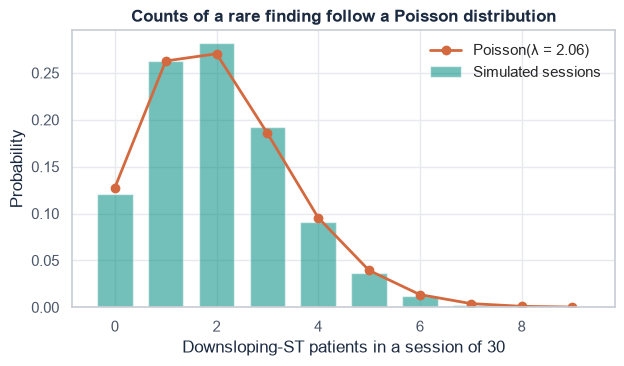

p(downsloping) = 0.069  ->  λ = 30 × p = 2.06
Simulated mean = 2.04, simulated variance = 1.91  (Poisson: both = λ)
P(no downsloping patient in a session) - simulated 0.121, Poisson 0.128


In [20]:
p_down = (df["ST_Slope"] == "Down").mean()
n_session = 30
lam = n_session * p_down
rng = np.random.default_rng(C.RANDOM_STATE)
is_down = (df["ST_Slope"] == "Down").to_numpy()
counts = is_down[rng.integers(0, len(df), size=(5000, n_session))].sum(axis=1)

ks = np.arange(0, counts.max() + 1)
observed = np.bincount(counts, minlength=len(ks)) / len(counts)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(ks, observed, color=C.TEAL, alpha=0.55, width=0.7, label="Simulated sessions")
ax.plot(ks, sps.poisson.pmf(ks, lam), "o-", color=C.CLASS_COLORS[1], lw=2, label=f"Poisson(λ = {lam:.2f})")
ax.set_xlabel("Downsloping-ST patients in a session of 30")
ax.set_ylabel("Probability")
ax.set_title("Counts of a rare finding follow a Poisson distribution")
ax.legend(frameon=False)
plots.save_fig(fig, "04_poisson_demo")
plt.show()

print(f"p(downsloping) = {p_down:.3f}  ->  λ = 30 × p = {lam:.2f}")
print(f"Simulated mean = {counts.mean():.2f}, simulated variance = {counts.var():.2f}  (Poisson: both = λ)")
print(f"P(no downsloping patient in a session) - simulated {observed[0]:.3f}, Poisson {sps.poisson.pmf(0, lam):.3f}")

The simulated counts match the Poisson curve closely and the mean ≈ variance ≈ λ, as the theory predicts.
(Strictly, the count is binomial with n = 30 and p ≈ 0.07; because p is small, Poisson is an excellent approximation.)

## Key Findings
* **Normality:** Shapiro-Wilk rejects normality for every feature (large n makes it very sensitive); Q-Q plots show Age and MaxHR are close to normal, Oldpeak and Cholesterol are skewed. The CLT justifies using mean-based tests anyway.
* **Welch t-test, MaxHR:** heart-disease patients have a much lower mean MaxHR (≈ 127.7 vs 148.2 bpm), p < 0.001 → **significant**.
* **Welch t-test, Age:** heart-disease patients are older on average (≈ 55.9 vs 50.6 years), p < 0.001 → **significant**.
* **ANOVA:** all five continuous features differ significantly between the two target groups. MaxHR also differs significantly across the 4 chest-pain types (asymptomatic patients have the lowest MaxHR); Cholesterol across chest-pain types is only *just* significant (p ≈ 0.048) - a weak effect that would disappear at α = 0.01.
* **Chi-square:** every categorical feature is significantly associated with heart disease; the strongest are **ST_Slope**, **ChestPainType** and **ExerciseAngina** (largest Cramér's V), the weakest is **RestingECG**.
* **One-sample Z-test:** the mean resting blood pressure (≈ 132.5 mm Hg) is significantly **above** the 120 mm Hg normal limit (z ≈ 21, p < 0.001) - this clinic-referred group is hypertensive on average.
* **95% CIs** for mean MaxHR do not overlap between the groups, confirming the t-test.
* **Type II errors (missed patients) are the dangerous mistake**, so recall is the key metric for model selection.
* The **Poisson** demo: counts of the rare downsloping-ST finding in sessions of 30 patients follow Poisson(λ ≈ 2.1), with mean ≈ variance.
* The **CLT demo** shows sample means of skewed Cholesterol become normal with spread σ/√n as the sample size grows.